# EV Energy Efficiency Prediction — Easy & Professional

**Simple Python | 18 steps | Clean graphs | Roman Urdu explanations**

**Project goal:** EV ki Energy Efficiency (km/kWh) predict karna.

**Kaise run karein:** CSV file ka naam `EV Energy Efficiency Dataset.csv` rakhein aur notebook ke saath same folder mein save karein. Phir upar se **Run All** karein.

**Graph samjho:** X-axis neeche, Y-axis side par hoti hai. Colors sirf data ko readable banate hain, accuracy ko change nahi karte.

## Step 1 — Libraries Import Karo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Step 2 — Dataset Load Karo

In [2]:
df = pd.read_csv("EV Energy Efficiency Dataset.csv")

print("Dataset rows and columns:", df.shape)
display(df.head())

Dataset rows and columns: (1197, 7)


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
0,2012,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
1,2012,Nissan,LEAF,Mid-size,80,7.0,4.739336
2,2013,Ford,Focus Electric,Compact,107,4.0,5.000000
3,2013,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
4,2013,Nissan,LEAF,Mid-size,80,7.0,4.739336


## Step 3 — Dataset Check Karo

Pehle columns, **real missing entries ka count**, aur duplicates check honge. `describe(include="all")` mein kabhi `NaN` is wajah se hota hai ke koi statistic us column par apply nahi hota — woh zaroori nahi ke missing data ho. Summary mein aise boxes ko `-` show kar rahe hain.

Neeche **Preview** mein missing numerical values ko median aur text values ko most common value se replace karke sirf display kiya jayega; original `df` change nahi hota.

In [3]:
print("All column names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Summary mein NaN ki jagah - show karo
# describe(include="all") ke kuch NaN missing data nahi, non-applicable statistics hain
display(df.describe(include="all").fillna("-"))

# Preview ke liye missing numeric values median se fill karo
# Original df change nahi hoga, model ki pipeline same rahegi
preview = df.copy()
for col in preview.columns:
    if preview[col].isnull().any():
        if pd.api.types.is_numeric_dtype(preview[col]):
            value = preview[col].median()
        else:
            common = preview[col].mode(dropna=True)
            value = common.iloc[0] if not common.empty else "Not available"
        if pd.isna(value):
            value = "Not available"
        preview[col] = preview[col].fillna(value)

print("\nPreview: missing values filled (original dataset unchanged)")
display(preview.head(10))

All column names:
['Model year', 'Make', 'Model', 'Vehicle class', 'Motor (kW)', 'Recharge time (h)', 'Energy Efficiency (km/kWh)']

Missing values in each column:
Model year                    0
Make                          0
Model                         0
Vehicle class                 0
Motor (kW)                    0
Recharge time (h)             0
Energy Efficiency (km/kWh)    0
dtype: int64

Duplicate rows: 0


C:\Users\Flex 5\AppData\Local\Temp\ipykernel_22884\2791149732.py:11: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(df.describe(include="all").fillna("-"))


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
count,1197.0,1197,1197,1197,1197.0,1197.0,1197.0
unique,-,37,590,12,-,-,-
top,-,Tesla,Niro EV,Sport utility vehicle: Standard,-,-,-
freq,-,176,8,311,-,-,-
mean,2023.231412,-,-,-,341.289891,10.547285,4.453765
std,2.881857,-,-,-,152.722951,2.706302,0.856691
min,2012.0,-,-,-,35.0,3.0,2.114165
25%,2022.0,-,-,-,230.0,8.5,3.787879
50%,2024.0,-,-,-,335.0,10.5,4.366812
75%,2025.0,-,-,-,420.0,12.0,5.102041



Preview: missing values filled (original dataset unchanged)


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
0,2012,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
1,2012,Nissan,LEAF,Mid-size,80,7.0,4.739336
2,2013,Ford,Focus Electric,Compact,107,4.0,5.000000
3,2013,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
4,2013,Nissan,LEAF,Mid-size,80,7.0,4.739336
5,2013,smart,fortwo electric drive cabriolet,Two-seater,35,8.0,5.102041
6,2013,smart,fortwo electric drive coupe,Two-seater,35,8.0,5.102041
7,2013,Tesla,Model S (40 kWh),Full-size,225,6.0,4.504505
8,2013,Tesla,Model S (60 kWh),Full-size,225,10.0,4.566210
9,2013,Tesla,Model S (85 kWh),Full-size,270,12.0,4.237288


## Step 4 — Data Cleaning

In [4]:
target_column = "Energy Efficiency (km/kWh)"

# Duplicate rows remove karo
df = df.drop_duplicates()

# Target column ko numeric banao
df[target_column] = pd.to_numeric(df[target_column], errors="coerce")

# Jis row mein target missing ho, us row ko remove karo
df = df.dropna(subset=[target_column])

print("Clean dataset shape:", df.shape)
display(df.head())

Clean dataset shape: (1197, 7)


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
0,2012,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
1,2012,Nissan,LEAF,Mid-size,80,7.0,4.739336
2,2013,Ford,Focus Electric,Compact,107,4.0,5.000000
3,2013,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
4,2013,Nissan,LEAF,Mid-size,80,7.0,4.739336


## Step 5 — Missing Values Ka Graph

**X-axis:** column names. **Y-axis:** har column mein missing entries ki quantity. Yeh graph Step 4 ki cleaning **ke baad** ka hai. Koi input column missing rahe to training pipeline usay median se fill karegi. Agar bars nahi hain, is stage par missing values nahi hain.

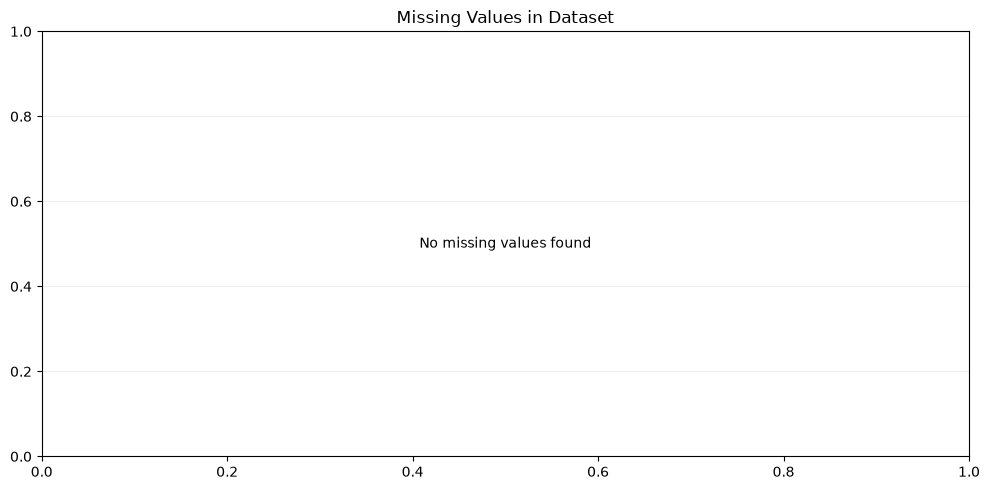

In [5]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0]

plt.figure(figsize=(10, 5))

if len(missing_values) > 0:
    plt.bar(missing_values.index, missing_values.values, color="teal")
    plt.xticks(rotation=75)
    plt.ylabel("Missing Values")
else:
    plt.text(0.5, 0.5, "No missing values found", ha="center", va="center")

plt.title("Missing Values in Dataset")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Step 6 — Efficiency Histogram Aur Boxplot

**Histogram:** X-axis efficiency ki ranges aur Y-axis un ranges mein EVs ki tadaad hai. `bins=20` 20 groups banata hai (20 EVs nahi). Orange dotted line **average efficiency** show karegi.

**Boxplot:** Beech ki orange line median hai; circles possible outliers hain (har outlier ghalat value nahi hoti).

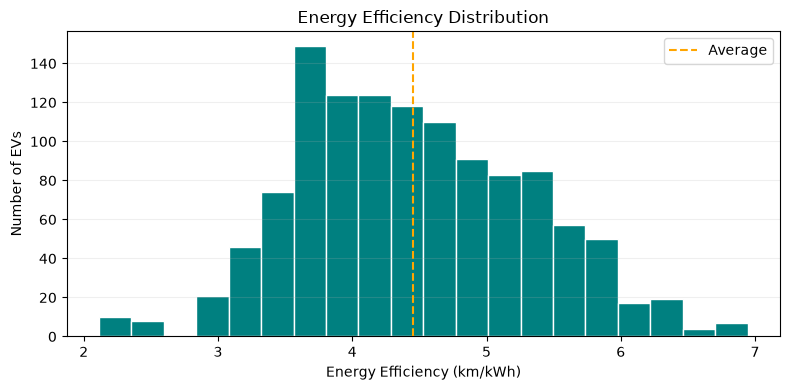

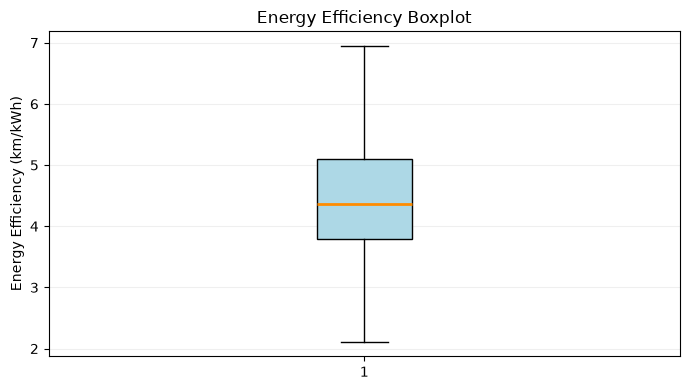

In [6]:
# Histogram
plt.figure(figsize=(8, 4))
plt.hist(df[target_column], bins=20, color="teal", edgecolor="white")
plt.axvline(df[target_column].mean(), color="orange", linestyle="--", label="Average")
plt.xlabel("Energy Efficiency (km/kWh)")
plt.ylabel("Number of EVs")
plt.title("Energy Efficiency Distribution")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

# Boxplot
plt.figure(figsize=(7, 4))
plt.boxplot(df[target_column], patch_artist=True,
            boxprops={"facecolor": "lightblue"},
            medianprops={"color": "darkorange", "linewidth": 2})
plt.ylabel("Energy Efficiency (km/kWh)")
plt.title("Energy Efficiency Boxplot")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Step 7 — Input Features vs Efficiency

Har dot **ek EV** ki row hai. Neeche X-axis par Model year, Motor power ya Recharge time hai; Y-axis par efficiency. Agar dots aksar upar ja rahe hon to positive trend ho sakta hai, neeche ja rahe hon to negative trend. Dots ka color teal sirf styling hai.

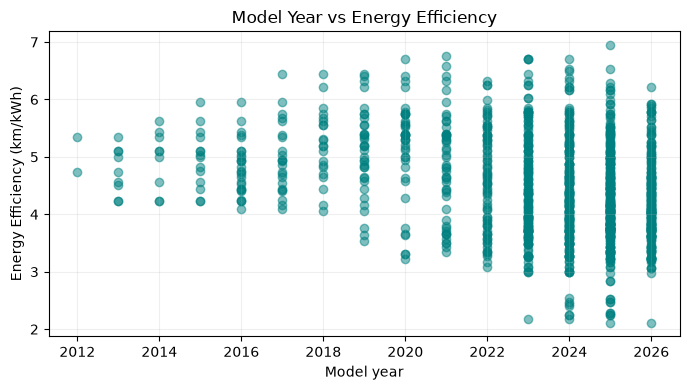

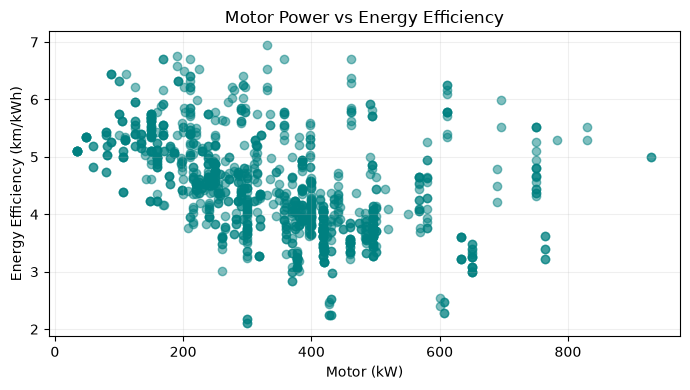

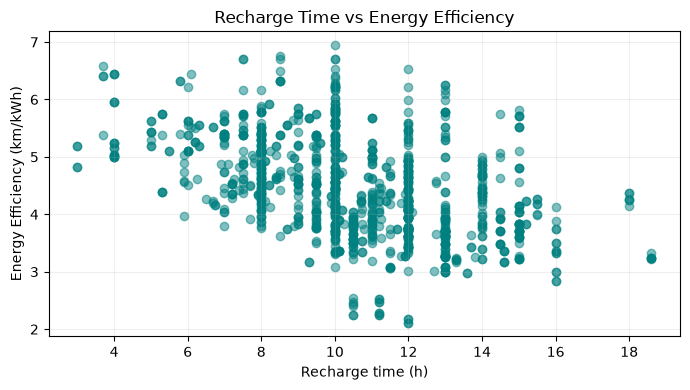

In [7]:
# Model year aur energy efficiency
plt.figure(figsize=(7, 4))
plt.scatter(df["Model year"], df[target_column], color="teal", alpha=0.5)
plt.xlabel("Model year")
plt.ylabel("Energy Efficiency (km/kWh)")
plt.title("Model Year vs Energy Efficiency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Motor power aur energy efficiency
plt.figure(figsize=(7, 4))
plt.scatter(df["Motor (kW)"], df[target_column], color="teal", alpha=0.5)
plt.xlabel("Motor (kW)")
plt.ylabel("Energy Efficiency (km/kWh)")
plt.title("Motor Power vs Energy Efficiency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Recharge time aur energy efficiency
plt.figure(figsize=(7, 4))
plt.scatter(df["Recharge time (h)"], df[target_column], color="teal", alpha=0.5)
plt.xlabel("Recharge time (h)")
plt.ylabel("Energy Efficiency (km/kWh)")
plt.title("Recharge Time vs Energy Efficiency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Step 8 — Correlation Heatmap

Har box **do columns ke relationship** ki reading show karta hai, -1 se +1 tak:

- `+1.00`: bohat strong positive relation; diagonal par same column ka apne saath 1 hota hai.
- `0.00`: linear relationship bohat kam ya nahi.
- `-1.00`: bohat strong negative relation.

**Colors:** Red positive, blue negative. `plt.text()` se numbers box ke andar aate hain. Agar kisi numeric column ka correlation calculate na ho sake to uska cell blank rahega.

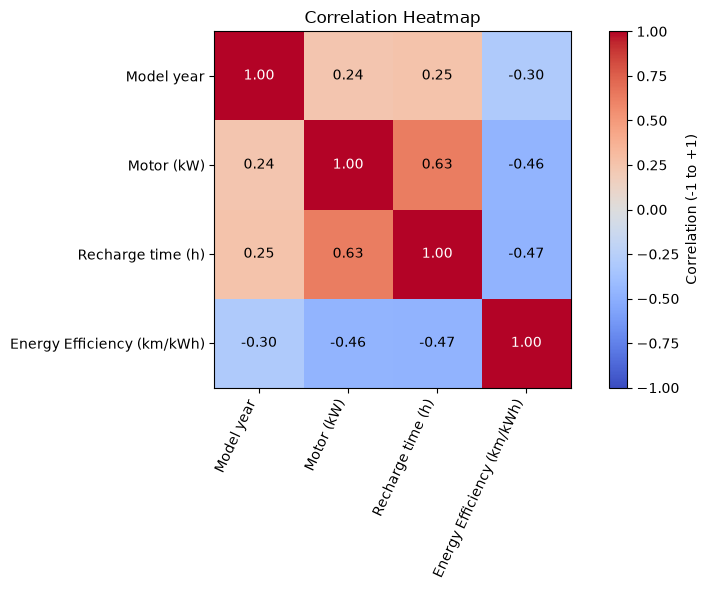

In [8]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(9, 6))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation (-1 to +1)")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=65, ha="right")
plt.yticks(range(len(correlation.columns)), correlation.columns)

# Har box mein number likho
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        value = correlation.iloc[i, j]
        if pd.notna(value):
            text_color = "white" if abs(value) > 0.7 else "black"
            plt.text(j, i, f"{value:.2f}", ha="center", va="center", color=text_color)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Step 9 — X Aur y Banao

In [9]:
# X mein target ke ilawa tamam columns hain
X = df.drop(columns=[target_column])

# y woh value hai jiski prediction karni hai
y = df[target_column]

# Text values ko numeric columns mein convert karo
X = pd.get_dummies(X, drop_first=True)

# Jo columns bilkul empty hain unko remove karo
X = X.dropna(axis=1, how="all")

print("Total input features:", X.shape[1])
print("Input feature names:")
print(X.columns.tolist())

display(X.head())

Total input features: 639
Input feature names:
['Model year', 'Motor (kW)', 'Recharge time (h)', 'Make_Audi', 'Make_BMW', 'Make_Cadillac', 'Make_Chevrolet', 'Make_Dodge', 'Make_FIAT', 'Make_Fisker', 'Make_Ford', 'Make_Ford ', 'Make_GMC', 'Make_Genesis', 'Make_Honda', 'Make_Hyundai', 'Make_Jaguar', 'Make_Jeep', 'Make_Kia', 'Make_Lexus', 'Make_Lucid', 'Make_MINI', 'Make_Mazda', 'Make_Mercedes-Benz', 'Make_Mitsubishi', 'Make_Nissan', 'Make_Polestar', 'Make_Porsche', 'Make_Rivian', 'Make_Rolls-Royce', 'Make_Subaru', 'Make_Tesla', 'Make_Tesla ', 'Make_Toyota', 'Make_VinFast', 'Make_Volkswagen', 'Make_Volvo', 'Make_smart', 'Make_smart EQ', 'Model_2 BST Edition', 'Model_2 Dual Motor', 'Model_2 Dual Motor (19" Wheels)', 'Model_2 Dual Motor (20" Wheels)', 'Model_2 Dual Motor Performance Pack', 'Model_2 Single Motor', 'Model_2 Single Motor (19" Wheels)', 'Model_2 Single Motor (20" Wheels)', 'Model_3 Long Range Dual Motor (20" Wheels)', 'Model_3 Long Range Dual Motor (21" Wheels)', 'Model_3 Long 

,Model year,Motor (kW),Recharge time (h),Make_Audi,Make_BMW,Make_Cadillac,Make_Chevrolet,Make_Dodge,Make_FIAT,Make_Fisker,...,Vehicle class_Mid-size,Vehicle class_Minicompact,Vehicle class_Minivan,Vehicle class_Pickup truck: Standard,Vehicle class_Sport utility vehicle: Small,Vehicle class_Sport utility vehicle: Standard,Vehicle class_Station wagon: Mid-size,Vehicle class_Station wagon: Small,Vehicle class_Subcompact,Vehicle class_Two-seater
0,2012,49,7.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,2012,80,7.0,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
2,2013,107,4.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,2013,49,7.0,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,2013,80,7.0,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False


## Step 10 — Training Aur Testing Data

**80% rows training, 20% testing:** `test_size=0.25` ka matlab 25% hota hai, isliye hum neeche original code mein 25% hi rakh rahe hain. `random_state=42` se random split repeatable hota hai. Printed counts real data se automatically nikalte hain.

In [10]:
# 75% data training ke liye, 25% testing ke liye
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 897
Testing rows: 300


## Step 11 — Pipeline Banao Aur Model Train Karo

**Pipeline** ka matlab hai ke missing values fill karna aur model train karna aik hi flow mein ho jayega. `fit()` model ko training data se sikhata hai.

In [11]:
pipeline = Pipeline([
    ("missing_values", SimpleImputer(strategy="median")),
    ("random_forest", RandomForestRegressor(n_estimators=100, random_state=42))
])

# Model ko training data do
pipeline.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


## Step 12 — Model Ki Performance

- **R²:** 1 ke qareeb ho to predictions generally better; 0 ya negative bhi ho sakta hai.
- **MAE:** Average absolute error (km/kWh). Kam ho to behtar.
- **RMSE:** Bari mistakes ko zyada weight deta hai. Kam ho to behtar.
- **Within 10% / 20%:** Kitni predictions actual nonzero value se itne percent ke andar hain. Zero actual values ko percentage calculation se exclude karte hain, warna division by zero ho sakta hai.

Model ab testing data par prediction karega. Regression project mein normal classification accuracy use nahi hoti. Is liye hum R², MAE, RMSE aur 10% / 20% error ke andar aane wali predictions ka percentage dekhenge.

In [12]:
predictions = pipeline.predict(X_test)

r2 = r2_score(y_test, predictions)
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

# Zero actual values ko percentage calculation se hatao
actual_values = y_test.to_numpy()
valid = actual_values != 0

if valid.sum() > 0:
    percentage_error = np.abs(actual_values[valid] - predictions[valid]) / np.abs(actual_values[valid]) * 100
    accuracy_10 = (percentage_error <= 10).mean() * 100
    accuracy_20 = (percentage_error <= 20).mean() * 100
    print("Predictions within 10% error:", round(accuracy_10, 2), "%")
    print("Predictions within 20% error:", round(accuracy_20, 2), "%")
else:
    print("Percentage error: Cannot calculate because actual values are zero")

print("R2 Score:", round(r2, 3))
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))

Predictions within 10% error: 91.67 %
Predictions within 20% error: 98.67 %
R2 Score: 0.911
MAE: 0.172
RMSE: 0.252


## Step 13 — Actual vs Predicted Values Ki Table

**Actual** = dataset ki asli efficiency. **Predicted** = model ka jawab. **Difference** = dono mein kitna farq. Difference chhota ho to prediction behtar. Sirf pehli 10 rows display kar rahe hain taake output clean rahe; poora `results` DataFrame available hai.

In [13]:
results = pd.DataFrame({
    "Actual Value": y_test,
    "Predicted Value": predictions
})

results["Difference"] = abs(results["Actual Value"] - results["Predicted Value"])

display(results.head(10).round(2))

,Actual Value,Predicted Value,Difference
921,4.15,4.01,0.14
321,4.57,4.00,0.57
101,4.44,4.41,0.04
920,3.83,3.86,0.03
58,4.41,4.31,0.10
790,2.29,2.42,0.13
948,3.62,4.02,0.39
969,3.83,3.96,0.13
410,3.08,3.30,0.23
1079,3.92,4.07,0.14


## Step 14 — Actual vs Predicted Graph

**X = actual efficiency**, **Y = predicted efficiency**. Har dot ek test EV hai. **Orange dashed line** perfect prediction (actual = predicted) ko show karti hai. Jitne dots line ke qareeb, utni prediction behtar. Graph mein R² bhi label par likha hai.

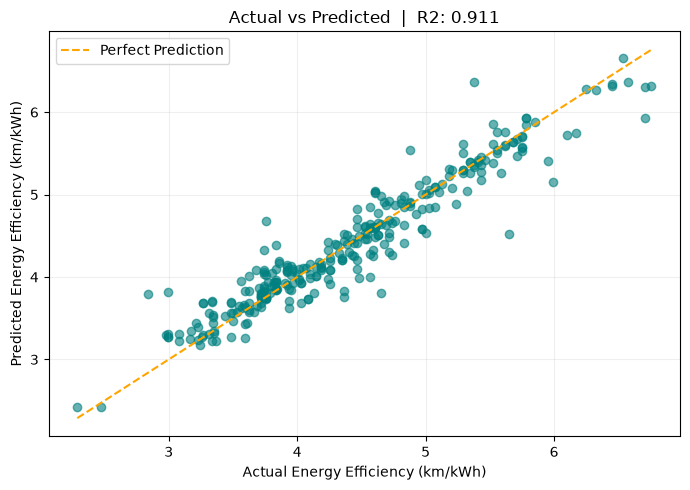

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, color="teal", alpha=0.6)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], "--", color="orange", label="Perfect Prediction")

plt.xlabel("Actual Energy Efficiency (km/kWh)")
plt.ylabel("Predicted Energy Efficiency (km/kWh)")
plt.title("Actual vs Predicted  |  R2: " + str(round(r2, 3)))
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Step 15 — Error Graphs

**Residual scatter:** Error = Actual − Predicted. Orange horizontal line zero error ko show karti hai. Dots agar 0 line ke qareeb hon to prediction better.

**Error histogram:** X-axis par error ranges, Y-axis par har range mein kitni predictions hain. `bins=20` 20 groups hain.

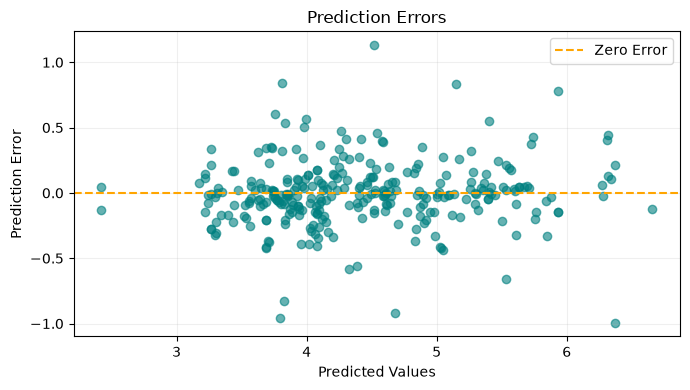

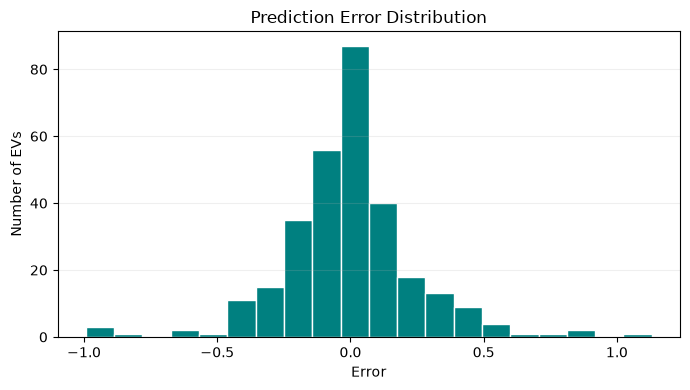

In [15]:
errors = y_test.to_numpy() - predictions

# Residual graph
plt.figure(figsize=(7, 4))
plt.scatter(predictions, errors, color="teal", alpha=0.6)
plt.axhline(y=0, color="orange", linestyle="--", label="Zero Error")
plt.xlabel("Predicted Values")
plt.ylabel("Prediction Error")
plt.title("Prediction Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Error distribution
plt.figure(figsize=(7, 4))
plt.hist(errors, bins=20, color="teal", edgecolor="white")
plt.xlabel("Error")
plt.ylabel("Number of EVs")
plt.title("Prediction Error Distribution")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Step 16 — Feature Importance

**Feature importance** ka matlab: model kis input ko prediction ke liye kitna use karta hai. Bar jitni lambi, utna zyada importance score. Ye **cause-and-effect ka proof nahi** hai. `head(15)` se sirf top 15 show honge.

Yeh graph batata hai ke Random Forest model ke liye kaun se input features zyada important rahe.

,Feature,Importance
1,Motor (kW),0.395
31,Make_Tesla,0.137
20,Make_Lucid,0.089
2,Recharge time (h),0.067
628,Vehicle class_Full-size,0.059
12,Make_GMC,0.038
634,Vehicle class_Sport utility vehicle: Standard,0.029
0,Model year,0.019
536,Model_VF8 PLUS Performance,0.016
15,Make_Hyundai,0.010


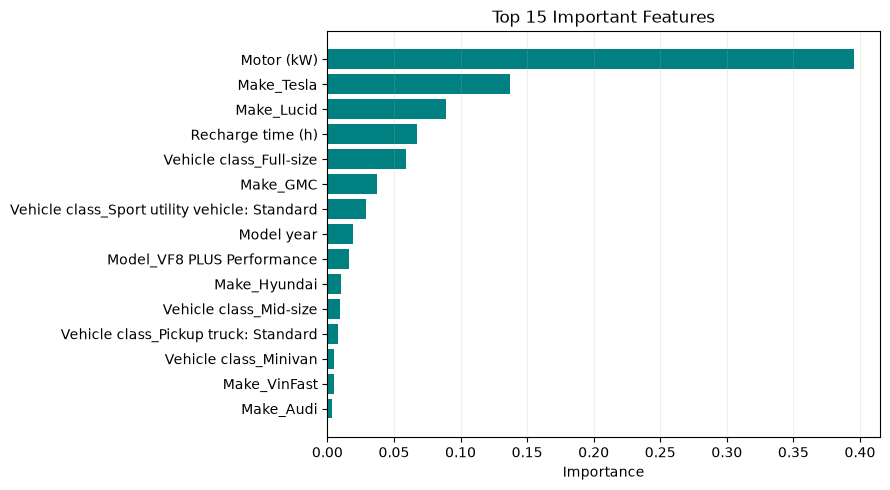

In [16]:
importance = pipeline.named_steps["random_forest"].feature_importances_

importance_data = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

importance_data = importance_data.sort_values(
    by="Importance", ascending=False
).head(15)

display(importance_data.round(3))

plt.figure(figsize=(9, 5))
plt.barh(importance_data["Feature"], importance_data["Importance"], color="teal")
plt.xlabel("Importance")
plt.title("Top 15 Important Features")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## Step 17 — New EV Ki Prediction

Neeche sample EV ke liye Model year, Motor aur Recharge time change kar sakte ho. Baqi input values pehli dataset row se li jayengi taake tamam required columns available hon.

In [17]:
new_ev = X.iloc[[0]].copy()

new_ev.loc[:, "Model year"] = 2024
new_ev.loc[:, "Motor (kW)"] = 150
new_ev.loc[:, "Recharge time (h)"] = 8

new_prediction = pipeline.predict(new_ev)

print("Predicted Energy Efficiency:", round(new_prediction[0], 2), "km/kWh")

Predicted Energy Efficiency: 5.32 km/kWh


## Step 18 — Model Save Karo

In [18]:
joblib.dump(pipeline, "ev_energy_efficiency_model.joblib")
print("Model saved successfully!")

Model saved successfully!


## Quick Revision — Graphs

| Graph | X-axis | Y-axis | Yaad rakhne wali baat |
|---|---|---|---|
| Missing Values | Column names | Missing rows ka count | Data cleaning check |
| Histogram | Efficiency / error ranges | EV count | `bins=20` = 20 ranges |
| Boxplot | Ek data group | Efficiency | Median + outliers |
| Scatter | Model year / Motor / Recharge | Efficiency | Har dot = 1 row |
| Heatmap | Numeric columns | Numeric columns | Box ke andar correlation number |
| Actual vs Predicted | Actual | Predicted | Orange line = perfect prediction |
| Residual plot | Predicted | Actual - Predicted | 0 line ideal |
| Feature importance | Importance score | Feature names | Lambi bar = zyada importance |

**Sir ke possible questions:** `alpha` = transparency; `figsize` = chart size; `tight_layout()` = labels ko cut hone se bachata hai; `plt.show()` = graph display; `plt.grid()` = halki reference lines.

## Final Project Summary

1. EV dataset load kiya, column names aur missing values check ki.
2. Duplicate rows aur missing target rows clean ki.
3. Histogram, boxplot, scatter aur heatmap se data samjha.
4. 75% train / 25% test split se Random Forest model train kiya.
5. R², MAE, RMSE aur prediction graphs se result check kiya.
6. Nayi EV ka sample prediction kiya aur model save kiya.

**Important:** Heatmap aur graphs data ko describe karte hain. Feature importance prediction mein model ki reliance show karta hai, proof of causation nahi. Agar training ke liye important feature column poora missing ho, dataset ki cleaning dobara dekhni hogi.